# CIFAR-10 Image Classification

Classify 32 x 32 RGB images into ten CIFAR-10 categories.

See [README.md](README.md) for data, setup, workflow, and evaluation notes.

In [1]:
import random
import numpy as np
import torch
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision.datasets import CIFAR10

In [3]:
#Datasets & DataLoaders

from torch.utils.data import DataLoader
import torchvision.transforms as transforms

#image => scale(0,1) => normalize => (-1,1)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

trainset = CIFAR10(root="./data",train=True,download=True,transform=transform)
testset = CIFAR10(root="./data",train=False,download=True,transform=transform)

In [4]:
trainloader = DataLoader(trainset,batch_size=64,shuffle=True)
testloader = DataLoader(testset,batch_size=64)

## Build the CNN

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN,self).__init__()

        self.conv_layer = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2), #kernel size = 2,stride = 2

            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),

            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2,2)            
        )

        self.fc_layers = nn.Sequential(
            nn.Linear(4*4*128,256),
            nn.ReLU(),

            nn.Linear(256,10)
        )

    def forward(self,x):
        x = self.conv_layer(x)
        x = torch.flatten(x,1) #flattening
        x = self.fc_layers(x)

        return x

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

model = CNN().to(device)

Using: cuda


In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

## Training the CNN

In [8]:
epochs = 10
train_losses = []

for epoch in range(epochs):
    model.train()
    epoch_training_loss = 0.0

    for images,labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        output = model(images) #FP
        loss = criterion(output,labels) # loss fnx
        loss.backward() #BP
        optimizer.step()

        epoch_training_loss += loss.item() * images.size(0)
    train_losses.append(epoch_training_loss/len(trainset))
    print(f"epoch = {epoch+1}/{epochs} & loss = {epoch_training_loss/len(trainset)}")

epoch = 1/10 & loss = 1.3919330095672608


epoch = 2/10 & loss = 0.9683038586235047


epoch = 3/10 & loss = 0.7760394785690308


epoch = 4/10 & loss = 0.6566621061325073


epoch = 5/10 & loss = 0.5557954609298706


epoch = 6/10 & loss = 0.45759319835662843


epoch = 7/10 & loss = 0.37826776012420654


epoch = 8/10 & loss = 0.3073150674343109


epoch = 9/10 & loss = 0.24246944005966187


epoch = 10/10 & loss = 0.19315546930789948


In [9]:
device = next(model.parameters()).device
model.eval()

correct_labels = 0
total_labels = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        correct_labels += (predicted == labels).sum().item()
        total_labels += labels.size(0)

print(f"Accuracy: {100 * correct_labels / total_labels:.2f}%")

Accuracy: 74.46%


## Learning curve and per-class evaluation
Evaluate the trained model on the held-out test set.

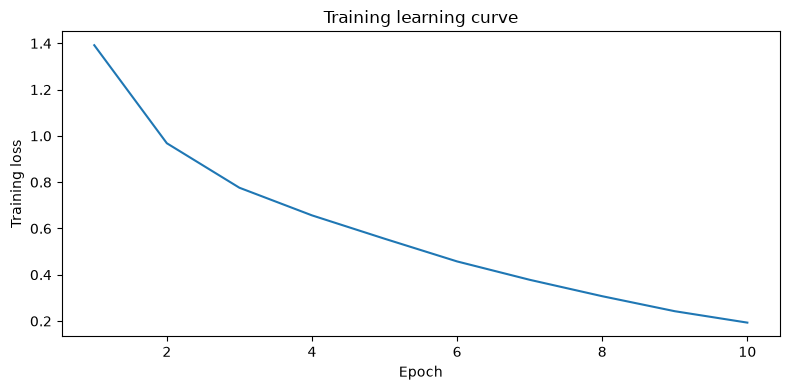

              precision    recall  f1-score   support

    airplane       0.70      0.84      0.77      1000
  automobile       0.87      0.83      0.85      1000
        bird       0.71      0.62      0.66      1000
         cat       0.58      0.55      0.56      1000
        deer       0.67      0.74      0.71      1000
         dog       0.63      0.68      0.66      1000
        frog       0.90      0.71      0.80      1000
       horse       0.74      0.81      0.77      1000
        ship       0.85      0.84      0.85      1000
       truck       0.84      0.81      0.83      1000

    accuracy                           0.74     10000
   macro avg       0.75      0.74      0.74     10000
weighted avg       0.75      0.74      0.74     10000

Test accuracy: 0.7446


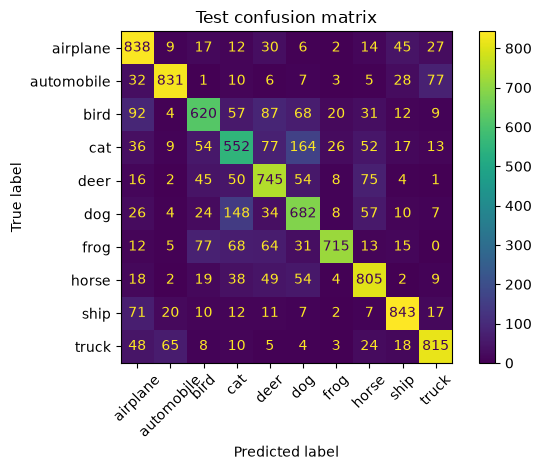

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training learning curve")
plt.tight_layout()
plt.show()

model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images.to(device))
        y_true.extend(labels.tolist())
        y_pred.extend(outputs.argmax(dim=1).cpu().tolist())
class_names = testset.classes

print(classification_report(y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, zero_division=0))
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}")
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(len(class_names))), display_labels=class_names, xticks_rotation=45)
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()


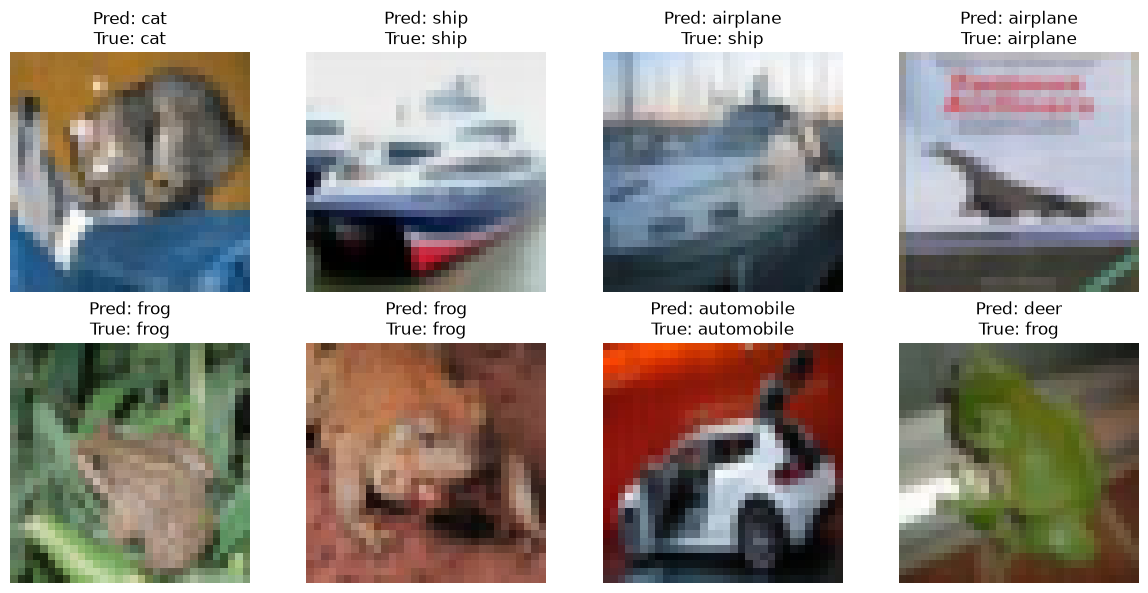

In [11]:
# Show real test images with their predicted and actual labels.
images, labels = next(iter(testloader))
with torch.no_grad():
    predicted = model(images[:8].to(device)).argmax(dim=1).cpu()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    image = (images[i] * 0.5 + 0.5).permute(1, 2, 0).numpy().clip(0, 1)
    ax.imshow(image)
    ax.set_title(f"Pred: {class_names[predicted[i]]}\nTrue: {class_names[labels[i]]}")
    ax.axis("off")
plt.tight_layout()
plt.show()
